# GRPO on top of the SFT model: age-conditioned readability (single T4)

**Why RL here.** SFT imitates reference answers token by token; it never directly optimizes "does this answer fit
the age the parent set". This notebook turns that into a reward and optimizes it with GRPO.

- **Start**: best SFT adapter merged into TinyLlama-1.1B-Chat; GRPO trains a new LoRA on top, KL to the SFT model
- **Rewards** (weights 1.0 / 0.5 / 0.3)
  - readability: distance between the answer's FKGL and the row's reference FKGL, the same quantity the
    evaluation measures (full reward within 2 grade levels, 0 at 5); see section 2 for why not an age-group band
  - relevance: MiniLM cosine similarity to the reference answer (blocks short, empty answers that farm readability)
  - format: no empty answers, no answers past the age group's length cap, no repetition loops
- **Data**: `yxpan/children_sft_dataset_v2` train / validation / test splits (the SFT notebook uses the same ones)
- **vLLM rollouts vs HF generate** (measured once in `grpo_v1`; set `RUN_SPEED_BENCH=True` to re-measure), two ways with everything else fixed:
  rollout throughput on the same prompts, and end-to-end GRPO step time for the same number of steps
- **Eval** on the SFT hold-out: base vs SFT vs SFT+GRPO, per age group, knowledge questions separately,
  an age-sensitivity sweep (same input, 5 set ages), and reward-hacking checks

Every run is a separate process and writes to Drive; finished runs are skipped on re-run.

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q -U vllm trl peft sentence-transformers textstat evaluate bert_score rouge_score
!pip uninstall -y -q torchao   # old Colab torchao breaks new PEFT at import time
# Installing vLLM can replace torch: restart the session once (Runtime -> Restart session), then run from the next cell

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 0. Config

In [ ]:
import os, json, time, gc, random, subprocess, sys
import numpy as np
import torch

BASE_MODEL = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
DATASET = "yxpan/children_sft_dataset_v2"   # v1 run: "yxpan/children_sft_dataset" (row-index split)

SFT_DIR = "/content/drive/MyDrive/llm_sft_runs/sft_lora_v2data"   # output of sft_lora_experiments.ipynb
SFT_BEST = "E_alpha64"          # E, not the best-by-BERTScore F: same test results, F's eval loss shows overfitting
                                 # (None = read best_config.json written by the SFT notebook)
EXP_NAME = "grpo_v2data"         # v1 run: "grpo_v1"
SEED = 42

GRPO = dict(
    lr=2e-5, lora_r=16, lora_alpha=32,
    lora_targets=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    num_generations=4,          # completions per prompt (the GRPO group)
    batch_completions=8,        # completions per device batch (= 2 prompts x 4)
    grad_accum=2,               # -> 16 completions (4 prompts) per optimizer step
    max_completion_length=160, temperature=0.9, beta=0.04,
    reward_weights=[1.0, 0.5, 0.3],   # readability, relevance, format
    vllm_gpu_mem=0.3, vllm_max_len=1024,
)
BENCH = dict(n_prompts=64, hf_batch_prompts=8, vllm_gpu_mem=0.5)
BENCH_STEPS = 20                 # GRPO steps per engine for the end-to-end speed comparison
RUN_SPEED_BENCH = False          # already measured on T4 in grpo_v1 (8.1x rollout, 2.2x step); True to re-measure
TRAIN_STEPS = 250
TRAIN_MODE = "vllm"              # engine for the main run; set to "hf" if vLLM does not work on this runtime

# evaluation (same generation settings as the SFT notebook)
GEN_KWARGS = dict(max_new_tokens=128, do_sample=True, temperature=0.8, top_p=0.9, top_k=30, repetition_penalty=1.05)
GEN_BATCH = 16
N_HOLDOUT = 600
AGE_SWEEP_N = 40                 # inputs for the age-sensitivity sweep (each generated at all 5 ages)
AGES = ["0-3", "4-6", "7-9", "10-13", "14-18"]

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = f"/content/drive/MyDrive/llm_rl_runs/{EXP_NAME}"
    WORK_DIR = "/content/rl_work"
except ImportError:
    OUT_DIR = os.path.join(os.environ.get("OUT_ROOT", os.path.expanduser("~/llm_rl_runs")), EXP_NAME)
    WORK_DIR = os.path.abspath("rl_work")
    SFT_DIR = os.environ.get("SFT_DIR", SFT_DIR)
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(WORK_DIR, exist_ok=True)
SFT_MERGED = os.path.join(WORK_DIR, "sft_merged")       # local disk: vLLM loads the model from this path
RL_CONFIG = os.path.join(OUT_DIR, "rl_config.json")

assert torch.cuda.is_available(), "No GPU: Runtime -> Change runtime type -> T4 GPU"
if SFT_BEST is None:
    SFT_BEST = json.load(open(f"{SFT_DIR}/best_config.json"))["best"]
print("SFT starting point:", SFT_BEST)
assert os.path.exists(f"{SFT_DIR}/{SFT_BEST}/adapter/adapter_model.safetensors"), \
    "SFT adapter not found: run sft_lora_experiments.ipynb first"
import transformers, trl, peft
transformers.logging.set_verbosity_error()
ENV = dict(gpu=torch.cuda.get_device_name(0), torch=torch.__version__, transformers=transformers.__version__,
           trl=trl.__version__, peft=peft.__version__)
try:
    import vllm; ENV["vllm"] = vllm.__version__
except Exception as e:
    ENV["vllm"] = f"not importable: {e}"
print(ENV); print("Outputs ->", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SFT starting point: E_alpha64
{'gpu': 'Tesla T4', 'torch': '2.14.0+cu130', 'transformers': '5.22.1', 'trl': '1.18.1', 'peft': '0.21.3', 'vllm': '0.34.0'}
Outputs -> /content/drive/MyDrive/llm_rl_runs/grpo_v2data


## 1. Merge the SFT adapter (fp16, so vLLM on T4 does not try bf16)

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import PeftModel

if not os.path.exists(os.path.join(SFT_MERGED, "config.json")):
    base = AutoModelForCausalLM.from_pretrained(BASE_MODEL, torch_dtype=torch.float16)
    merged = PeftModel.from_pretrained(base, f"{SFT_DIR}/{SFT_BEST}/adapter").merge_and_unload()
    merged.save_pretrained(SFT_MERGED)
    AutoTokenizer.from_pretrained(BASE_MODEL).save_pretrained(SFT_MERGED)
    del base, merged; gc.collect()
merged_cfg = json.load(open(os.path.join(SFT_MERGED, "config.json")))
print("merged model dtype:", merged_cfg.get("torch_dtype", merged_cfg.get("dtype")))

merged model dtype: float16


## 2. Data, reward targets, and the reward functions

**Readability reward: per-row reference FKGL, not an age-group band.** The v1 run rewarded FKGL inside the age
group's band (25th-75th percentile of training references). Two problems, both visible in the data:

- the band is not what the evaluation measures (distance to each row's own reference), and on v1 GRPO moved the
  reward but barely moved the hold-out metric
- the SFT failure analysis on v2 shows 10-13 and 14-18 answers are too simple (median FKGL 0.9 below the reference),
  yet their median answer FKGL (8.4 and 9.9) sits inside those groups' bands, so the band reward gives those
  answers full credit and no push upward

The reward now is the evaluation criterion itself: 1 when the answer is within 2 grade levels of the row's
reference FKGL, falling linearly to 0 at 5. The v2 data pipeline already removed references with outlier FKGL
for their age group, which limits noise in the per-row targets.

Bands and length caps still come from the **training** references only, per age group: bands are kept for
reporting, the length cap is used by the format reward.


In [ ]:
import textstat
from datasets import load_dataset

dsd = load_dataset(DATASET)
if {"train", "validation", "test"} <= set(dsd.keys()):   # v2: fixed stratified splits (same as the SFT notebook)
    train_ds, eval_ds, holdout_ds = dsd["train"], dsd["validation"], dsd["test"]
else:                                                  # v1: a single split, cut by row index
    ds = dsd["train"]
    train_ds, eval_ds = ds.select(range(500)), ds.select(range(500, 600))
    holdout_ds = ds.select(range(600, min(600 + N_HOLDOUT, len(ds))))
TRAIN_ROWS, EVAL_ROWS, HOLDOUT_ROWS = list(train_ds), list(eval_ds), list(holdout_ds)

def system_prompt(age):
    return (f"You are talking to a child aged {age}. "
            f"Generate a friendly response with age-appropriate knowledge.")

def prompt_messages(age, instruction):
    return [{"role": "system", "content": system_prompt(age)}, {"role": "user", "content": instruction}]

def fkgl(t):
    return float(textstat.flesch_kincaid_grade(t)) if t.strip() else float("nan")

band, max_words = {}, {}
for age in AGES:
    refs = [r["response"] for r in TRAIN_ROWS if r["age"] == age]
    if len(refs) < 20:
        print(f"{age}: only {len(refs)} training rows, no band (this age gets no readability reward)")
        continue
    f = np.array([fkgl(t) for t in refs])
    band[age] = [round(float(np.nanpercentile(f, 25)), 2), round(float(np.nanpercentile(f, 75)), 2)]
    max_words[age] = int(1.5 * np.percentile([len(t.split()) for t in refs], 75))
print("FKGL band per age:", band); print("length cap (words):", max_words)

train_file = os.path.join(OUT_DIR, "rl_train.jsonl")
with open(train_file, "w") as f:
    for r in TRAIN_ROWS:
        ref_fkgl = fkgl(r["response"])
        if r["age"] in band and not np.isnan(ref_fkgl):
            f.write(json.dumps(dict(prompt=prompt_messages(r["age"], r["instruction"]), age=r["age"],
                                    reference=r["response"], ref_fkgl=ref_fkgl)) + "\n")

RL_CFG = dict(sft_merged=SFT_MERGED, train_file=train_file, out_dir=OUT_DIR, work_dir=WORK_DIR, seed=SEED,
              fkgl_band=band, max_words=max_words, fkgl_full=2.0, fkgl_zero=5.0,
              embed_model="sentence-transformers/all-MiniLM-L6-v2", grpo=GRPO, bench=BENCH, env=ENV)
json.dump(RL_CFG, open(RL_CONFIG, "w"), indent=1)
os.environ["RL_CONFIG"] = RL_CONFIG

FKGL band per age: {'0-3': [1.09, 4.06], '4-6': [1.85, 4.64], '7-9': [5.93, 8.12], '10-13': [7.59, 10.0], '14-18': [9.55, 13.26]}
length cap (words): {'0-3': 42, '4-6': 55, '7-9': 124, '10-13': 141, '14-18': 169}


In [ ]:
RL_REWARDS = '"""Reward functions for GRPO: readability relative to the reference, relevance to the reference, format.\nThe config path is read from the RL_CONFIG environment variable."""\nimport json\nimport os\n\nimport numpy as np\nimport textstat\n\n_CFG = None\n_EMB = None\n\n\ndef cfg():\n    global _CFG\n    if _CFG is None:\n        with open(os.environ["RL_CONFIG"]) as f:\n            _CFG = json.load(f)\n    return _CFG\n\n\ndef _text(c):\n    # conversational completions look like [{"role": "assistant", "content": "..."}]\n    if isinstance(c, list):\n        return c[0]["content"] if c else ""\n    return c or ""\n\n\ndef fkgl(text):\n    return float(textstat.flesch_kincaid_grade(text)) if text.strip() else float("nan")\n\n\ndef readability_reward(completions, ref_fkgl, **kwargs):\n    """Distance between the answer\'s FKGL and this row\'s reference FKGL, the quantity the evaluation measures:\n    1 within `fkgl_full` grade levels (the evaluation\'s "within 2"), falling linearly to 0 at `fkgl_zero`."""\n    full, zero = cfg()["fkgl_full"], cfg()["fkgl_zero"]\n    out = []\n    for c, target in zip(completions, ref_fkgl):\n        g = fkgl(_text(c))\n        if target is None or np.isnan(g) or np.isnan(target):\n            out.append(0.0)\n            continue\n        out.append(float(np.clip((zero - abs(g - target)) / (zero - full), 0.0, 1.0)))\n    return out\n\n\ndef get_embedder():\n    global _EMB\n    if _EMB is None:\n        import torch\n        from sentence_transformers import SentenceTransformer\n        _EMB = SentenceTransformer(cfg()["embed_model"], device="cuda" if torch.cuda.is_available() else "cpu")\n    return _EMB\n\n\ndef relevance_reward(completions, reference, **kwargs):\n    """Cosine similarity to the reference answer, so short empty answers can\'t farm the readability reward."""\n    texts = [_text(c) for c in completions]\n    emb = get_embedder()\n    a = emb.encode(texts, normalize_embeddings=True, convert_to_numpy=True)\n    b = emb.encode(list(reference), normalize_embeddings=True, convert_to_numpy=True)\n    sims = (a * b).sum(axis=1)\n    return [float(max(0.0, s)) if t.strip() else 0.0 for s, t in zip(sims, texts)]\n\n\ndef distinct_ratio(text, n=3):\n    w = text.lower().split()\n    grams = [tuple(w[i:i + n]) for i in range(len(w) - n + 1)]\n    return len(set(grams)) / len(grams) if grams else 1.0\n\n\ndef format_reward(completions, age, **kwargs):\n    """Penalize empty answers, answers longer than the age group\'s length cap, and repetition loops."""\n    out = []\n    for c, a in zip(completions, age):\n        t = _text(c).strip()\n        if not t:\n            out.append(0.0)\n            continue\n        r = 1.0\n        n, cap = len(t.split()), cfg()["max_words"].get(a, 200)\n        if n > cap:\n            r -= min(1.0, (n - cap) / cap)\n        if distinct_ratio(t) < 0.6:\n            r -= 0.5\n        out.append(max(0.0, r))\n    return out\n\n\nREWARD_FUNCS = [readability_reward, relevance_reward, format_reward]\n'
GRPO_TRAIN = '"""One GRPO run per process (so HF and vLLM runs never share GPU state).\npython grpo_train.py --config rl_config.json --mode hf|vllm --steps N --name RUN [--save]"""\nimport argparse\nimport json\nimport os\nimport sys\nimport time\n\n\ndef main(argv=None):\n    ap = argparse.ArgumentParser()\n    ap.add_argument("--config", required=True)\n    ap.add_argument("--mode", choices=["hf", "vllm"], required=True)\n    ap.add_argument("--steps", type=int, required=True)\n    ap.add_argument("--name", required=True)\n    ap.add_argument("--save", action="store_true", help="save the LoRA adapter")\n    ap.add_argument("--device", default="cuda", help="\'cpu\' only for smoke tests")\n    a = ap.parse_args(argv)\n\n    os.environ["RL_CONFIG"] = a.config\n    cfg = json.load(open(a.config))\n    run_dir = os.path.join(cfg["out_dir"], "runs", a.name)\n    adapter_file = os.path.join(run_dir, "adapter", "adapter_model.safetensors")\n    if os.path.exists(os.path.join(run_dir, "summary.json")) and (not a.save or os.path.exists(adapter_file)):\n        print(f"[{a.name}] already done, skipping")\n        return\n    os.makedirs(run_dir, exist_ok=True)\n\n    import torch\n    from datasets import load_dataset\n    from peft import LoraConfig\n    from transformers import AutoModelForCausalLM, AutoTokenizer\n    from trl import GRPOConfig, GRPOTrainer\n    sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))\n    import rl_rewards\n\n    cpu = a.device == "cpu"\n    g = cfg["grpo"]\n    tok = AutoTokenizer.from_pretrained(cfg["sft_merged"])\n    if tok.pad_token is None:\n        tok.pad_token = tok.eos_token\n    model = AutoModelForCausalLM.from_pretrained(cfg["sft_merged"], torch_dtype=torch.float32 if cpu else torch.float16)\n    train = load_dataset("json", data_files=cfg["train_file"])["train"]\n\n    args = GRPOConfig(\n        output_dir=os.path.join(cfg["work_dir"], a.name), max_steps=a.steps, learning_rate=g["lr"],\n        per_device_train_batch_size=g["batch_completions"], num_generations=g["num_generations"],\n        gradient_accumulation_steps=g["grad_accum"], max_completion_length=g["max_completion_length"],\n        temperature=g["temperature"], beta=g["beta"], reward_weights=g["reward_weights"],\n        logging_steps=1, save_strategy="no", report_to="none", seed=cfg["seed"],\n        fp16=not cpu, bf16=False, use_cpu=cpu,\n        use_vllm=a.mode == "vllm", vllm_mode="colocate", vllm_gpu_memory_utilization=g["vllm_gpu_mem"],\n        vllm_max_model_length=g["vllm_max_len"],\n    )\n    peft_cfg = LoraConfig(r=g["lora_r"], lora_alpha=g["lora_alpha"], lora_dropout=0.05,\n                          target_modules=g["lora_targets"], bias="none", task_type="CAUSAL_LM")\n    trainer = GRPOTrainer(model=model, reward_funcs=rl_rewards.REWARD_FUNCS, args=args, train_dataset=train,\n                          processing_class=tok, peft_config=peft_cfg)\n    if not cpu:\n        torch.cuda.reset_peak_memory_stats()\n    t0 = time.time()\n    trainer.train()\n    wall = time.time() - t0\n\n    json.dump(trainer.state.log_history, open(os.path.join(run_dir, "log_history.json"), "w"), indent=1)\n    if a.save:\n        trainer.model.save_pretrained(os.path.join(run_dir, "adapter"))\n        tok.save_pretrained(os.path.join(run_dir, "adapter"))\n    summary = dict(name=a.name, mode=a.mode, steps=a.steps, wall_s=round(wall, 1),\n                   gpu=None if cpu else torch.cuda.get_device_name(0),\n                   peak_torch_mem_gb=None if cpu else round(torch.cuda.max_memory_allocated() / 1e9, 2))\n    json.dump(summary, open(os.path.join(run_dir, "summary.json"), "w"), indent=1)\n    print(summary)\n\n\nif __name__ == "__main__":\n    main()\n'
ROLLOUT_BENCH = '"""Rollout throughput: HF generate vs vLLM on the same prompts with the same sampling settings.\nOne engine per process. python rollout_bench.py --config rl_config.json --engine hf|vllm"""\nimport argparse\nimport json\nimport os\nimport time\n\n\ndef main(argv=None):\n    ap = argparse.ArgumentParser()\n    ap.add_argument("--config", required=True)\n    ap.add_argument("--engine", choices=["hf", "vllm"], required=True)\n    a = ap.parse_args(argv)\n    cfg = json.load(open(a.config))\n    out_path = os.path.join(cfg["out_dir"], f"rollout_bench_{a.engine}.json")\n    if os.path.exists(out_path):\n        print("already done:", json.load(open(out_path)))\n        return\n\n    import torch\n    from transformers import AutoTokenizer\n    b, g = cfg["bench"], cfg["grpo"]\n    tok = AutoTokenizer.from_pretrained(cfg["sft_merged"])\n    if tok.pad_token is None:\n        tok.pad_token = tok.eos_token\n    rows = [json.loads(l) for l in open(cfg["train_file"])][: b["n_prompts"]]\n    texts = [tok.apply_chat_template(r["prompt"], tokenize=False, add_generation_prompt=True) for r in rows]\n    n, max_new, temp = g["num_generations"], g["max_completion_length"], g["temperature"]\n    device = "cuda" if torch.cuda.is_available() else "cpu"\n\n    if a.engine == "hf":\n        from transformers import AutoModelForCausalLM\n        model = AutoModelForCausalLM.from_pretrained(\n            cfg["sft_merged"], torch_dtype=torch.float16 if device == "cuda" else torch.float32).to(device).eval()\n        tok.padding_side = "left"\n\n        @torch.no_grad()\n        def run(batch_texts):\n            tokens = 0\n            for i in range(0, len(batch_texts), b["hf_batch_prompts"]):\n                enc = tok(batch_texts[i:i + b["hf_batch_prompts"]], return_tensors="pt", padding=True,\n                          add_special_tokens=False).to(device)\n                out = model.generate(**enc, do_sample=True, temperature=temp, max_new_tokens=max_new,\n                                     num_return_sequences=n, pad_token_id=tok.pad_token_id)\n                gen = out[:, enc["input_ids"].shape[1]:]\n                tokens += int((gen != tok.pad_token_id).sum())\n            return tokens\n\n        run(texts[:2])  # warmup\n        if device == "cuda":\n            torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()\n        t0 = time.time(); tokens = run(texts)\n        if device == "cuda":\n            torch.cuda.synchronize()\n        secs = time.time() - t0\n        mem = round(torch.cuda.max_memory_allocated() / 1e9, 2) if device == "cuda" else None\n    else:\n        from vllm import LLM, SamplingParams\n        llm = LLM(model=cfg["sft_merged"], dtype="float16", gpu_memory_utilization=b["vllm_gpu_mem"],\n                  max_model_len=g["vllm_max_len"], seed=cfg["seed"])\n        sp = SamplingParams(n=n, temperature=temp, max_tokens=max_new, seed=cfg["seed"])\n        llm.generate(texts[:2], sp)  # warmup\n        t0 = time.time(); outs = llm.generate(texts, sp); secs = time.time() - t0\n        tokens = sum(len(o.token_ids) for r in outs for o in r.outputs)\n        mem = None  # vLLM pre-allocates gpu_memory_utilization of the GPU; peak torch memory is not meaningful\n\n    res = dict(engine=a.engine, n_prompts=len(texts), completions=len(texts) * n, completion_tokens=tokens,\n               seconds=round(secs, 2), tokens_per_s=round(tokens / secs, 1),\n               completions_per_s=round(len(texts) * n / secs, 2), peak_torch_mem_gb=mem,\n               gpu=torch.cuda.get_device_name(0) if device == "cuda" else "cpu")\n    json.dump(res, open(out_path, "w"), indent=1)\n    print(res)\n\n\nif __name__ == "__main__":\n    main()\n'

for name, src in [("rl_rewards.py", RL_REWARDS), ("grpo_train.py", GRPO_TRAIN), ("rollout_bench.py", ROLLOUT_BENCH)]:
    with open(os.path.join(WORK_DIR, name), "w") as f:
        f.write(src)
sys.path.insert(0, WORK_DIR)
import importlib, rl_rewards
importlib.reload(rl_rewards)
print(os.listdir(WORK_DIR))

['sft_merged', 'rl_rewards.py', 'grpo_main', 'grpo_train.py', 'rollout_bench.py', '__pycache__']


## 3. Check the rewards before training

Reference answers score 1 on readability by construction (distance 0 to themselves), so the useful check is
SFT vs base: SFT should score clearly higher.
If not, the reward is measuring the wrong thing and must be fixed before any RL.

In [ ]:
import pandas as pd

def load_preds(path):
    return [json.loads(l) for l in open(path)] if os.path.exists(path) else None

def score(texts, rows):
    as_completion = [[{"role": "assistant", "content": t}] for t in texts]
    ages, refs = [r["age"] for r in rows], [r["response"] if "response" in r else r["reference"] for r in rows]
    ref_fk = [fkgl(t) for t in refs]
    keep = [i for i, a in enumerate(ages) if a in band]
    sel = lambda xs: [xs[i] for i in keep]
    return dict(readability=np.mean(rl_rewards.readability_reward(sel(as_completion), sel(ref_fk))),
                relevance=np.mean(rl_rewards.relevance_reward(sel(as_completion), sel(refs))),
                format=np.mean(rl_rewards.format_reward(sel(as_completion), sel(ages))), n=len(keep))

checks = {"reference answers": score([r["response"] for r in EVAL_ROWS], EVAL_ROWS)}
for label, path in [("base model", f"{SFT_DIR}/base/eval_preds.jsonl"),
                    (f"SFT ({SFT_BEST})", f"{SFT_DIR}/{SFT_BEST}/eval_preds.jsonl")]:
    preds = load_preds(path)
    if preds:
        checks[label] = score([p["prediction"] for p in preds], [dict(age=p["age"], response=p["reference"]) for p in preds])
reward_check = pd.DataFrame(checks).T
reward_check["weighted"] = reward_check[["readability", "relevance", "format"]].values @ np.array(GRPO["reward_weights"])
display(reward_check.round(3))
reward_check.to_csv(f"{OUT_DIR}/reward_check.csv")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,readability,relevance,format,n,weighted
reference answers,1.000,1.000,0.955,100.0,1.786
base model,0.596,0.574,0.716,100.0,1.098
SFT (E_alpha64),0.794,0.642,0.978,100.0,1.408


## 4. vLLM vs HF generate: rollout throughput

Same 64 training prompts, 4 samples each, same temperature and max length. Each engine runs in its own process.

In [ ]:
def run_script(*args):
    cmd = [sys.executable, os.path.join(WORK_DIR, args[0])] + list(args[1:])
    print(" ".join(cmd))
    p = subprocess.run(cmd, env=dict(os.environ, RL_CONFIG=RL_CONFIG), capture_output=True, text=True)
    print(p.stdout[-2000:])
    if p.returncode != 0:
        print(p.stderr[-4000:])
        raise RuntimeError(f"{args[0]} failed (exit {p.returncode})")

for engine in (["hf", "vllm"] if RUN_SPEED_BENCH else []):
    try:
        run_script("rollout_bench.py", "--config", RL_CONFIG, "--engine", engine)
    except RuntimeError as e:
        print(e)

## 5. vLLM vs HF generate: end-to-end GRPO step time

Same config, same seed, `BENCH_STEPS` steps each; only the generation engine changes.
The first 2 steps are dropped as warmup.

In [ ]:
for mode in (["hf", "vllm"] if RUN_SPEED_BENCH else []):
    try:
        run_script("grpo_train.py", "--config", RL_CONFIG, "--mode", mode, "--steps", str(BENCH_STEPS),
                   "--name", f"bench_{mode}")
    except RuntimeError as e:
        print(e)

In [ ]:
import matplotlib.pyplot as plt

if not RUN_SPEED_BENCH:
    print("Speed comparison skipped (RUN_SPEED_BENCH=False). T4 results: llm_rl_runs/grpo_v1/vllm_vs_hf_speed.csv")
else:
    def step_stats(name):
        p = f"{OUT_DIR}/runs/{name}/log_history.json"
        if not os.path.exists(p):
            return None
        hist = [h for h in json.load(open(p)) if "step_time" in h][2:]
        st = np.array([h["step_time"] for h in hist])
        length = np.array([h.get("completions/mean_length", np.nan) for h in hist])
        per_step = GRPO["batch_completions"] * GRPO["grad_accum"]
        return dict(step_time_s=st.mean(), step_time_std=st.std(), mean_completion_len=np.nanmean(length),
                    train_tokens_per_s=np.nanmean(per_step * length / st), steps_measured=len(st))

    rows = {}
    for engine in ["hf", "vllm"]:
        rb = f"{OUT_DIR}/rollout_bench_{engine}.json"
        r = json.load(open(rb)) if os.path.exists(rb) else {}
        s = step_stats(f"bench_{engine}") or {}
        rows[engine] = dict(rollout_tokens_per_s=r.get("tokens_per_s"), rollout_seconds=r.get("seconds"), **s)
    speed = pd.DataFrame(rows).T
    if {"hf", "vllm"} <= set(speed.index) and speed.notna().all().all():
        speed.loc["vllm speedup (x)"] = [speed.loc["vllm", c] / speed.loc["hf", c] if "per_s" in c else
                                         speed.loc["hf", c] / speed.loc["vllm", c] if c in ("rollout_seconds", "step_time_s") else np.nan
                                         for c in speed.columns]
    display(speed.round(2))
    speed.to_csv(f"{OUT_DIR}/vllm_vs_hf_speed.csv")

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, col, title in [(axes[0], "rollout_tokens_per_s", "Rollout throughput (tokens/s)"),
                           (axes[1], "step_time_s", "GRPO step time (s)")]:
        if col in speed.columns:
            vals = speed.loc[[e for e in ["hf", "vllm"] if e in speed.index], col]
            ax.bar(vals.index, vals.values, color=["#888", "#3a7"]); ax.set_title(title)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/vllm_vs_hf_speed.png", dpi=150); plt.show()

Speed comparison skipped (RUN_SPEED_BENCH=False). T4 results: llm_rl_runs/grpo_v1/vllm_vs_hf_speed.csv


## 6. Main GRPO run

In [ ]:
run_script("grpo_train.py", "--config", RL_CONFIG, "--mode", TRAIN_MODE, "--steps", str(TRAIN_STEPS),
           "--name", "grpo_main", "--save")

/usr/bin/python3 /content/rl_work/grpo_train.py --config /content/drive/MyDrive/llm_rl_runs/grpo_v2data/rl_config.json --mode vllm --steps 250 --name grpo_main --save
at_reward/std': '0', 'reward': '1.557', 'reward_std': '0.2288', 'frac_reward_zero_std': '0', 'sampling/sampling_logp_difference/mean': '0.00294', 'sampling/sampling_logp_difference/max': '0.04602', 'sampling/importance_sampling_ratio/min': '0.9415', 'sampling/importance_sampling_ratio/mean': '1.005', 'sampling/importance_sampling_ratio/max': '1.062', 'kl': '0.003325', 'entropy': '1.229', 'clip_ratio/low_mean': '0', 'clip_ratio/high_mean': '0', 'clip_ratio/region_mean': '0', 'clip_ratio/low_min': '0', 'clip_ratio/high_max': '0', 'step_time': '5.037', 'epoch': '1.423'}
{'loss': '-0.07162', 'grad_norm': '0.5883', 'learning_rate': '8e-08', 'num_tokens': '5.508e+05', 'completions/mean_length': '93.62', 'completions/min_length': '26', 'completions/max_length': '160', 'completions/clipped_ratio': '0.125', 'completions/mean_termi

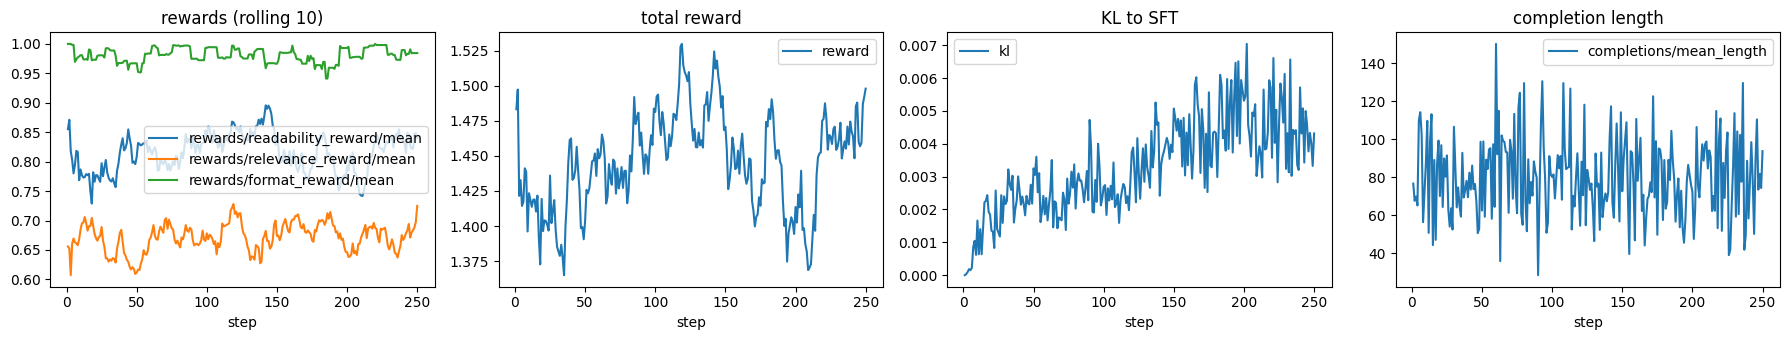

In [ ]:
hist = json.load(open(f"{OUT_DIR}/runs/grpo_main/log_history.json"))
h = pd.DataFrame([x for x in hist if "reward" in x]).set_index("step")
reward_cols = [c for c in h.columns if c.startswith("rewards/") and c.endswith("/mean")]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
h[reward_cols].rolling(10, min_periods=1).mean().plot(ax=axes[0], title="rewards (rolling 10)")
h[["reward"]].rolling(10, min_periods=1).mean().plot(ax=axes[1], title="total reward")
if "kl" in h: h[["kl"]].plot(ax=axes[2], title="KL to SFT")
if "completions/mean_length" in h: h[["completions/mean_length"]].plot(ax=axes[3], title="completion length")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/grpo_training_curves.png", dpi=150); plt.show()

## 7. Evaluation: base vs SFT vs SFT+GRPO on the hold-out set

Same generation settings and seed as the SFT notebook. Base and SFT hold-out predictions are reused from the
SFT run when available. Knowledge questions use `needs_knowledge` when the dataset has it
(v2), otherwise `intent == "scientific question"`.

In [ ]:
import evaluate
rouge, bertscore = evaluate.load("rouge"), evaluate.load("bertscore")
tok = AutoTokenizer.from_pretrained(SFT_MERGED)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

@torch.no_grad()
def generate(model, prompts):
    tok.padding_side = "left"; torch.manual_seed(SEED); out_text = []
    for i in range(0, len(prompts), GEN_BATCH):
        texts = [tok.apply_chat_template(p, tokenize=False, add_generation_prompt=True) for p in prompts[i:i + GEN_BATCH]]
        enc = tok(texts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        out = model.generate(**enc, **GEN_KWARGS, pad_token_id=tok.pad_token_id)
        out_text += tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [t.strip() for t in out_text]

def text_metrics(preds, rows):
    refs = [r["response"] for r in rows]
    gap = np.abs(np.array([fkgl(p) for p in preds]) - np.array([fkgl(t) for t in refs]))
    return dict(n=len(rows),
                bert_f1=float(np.mean(bertscore.compute(predictions=preds, references=refs, lang="en", batch_size=32)["f1"])),
                rougeL=float(rouge.compute(predictions=preds, references=refs)["rougeL"]),
                fkgl_gap=float(np.nanmean(gap)), fkgl_within2=float(np.nanmean(gap <= 2)),
                mean_words=float(np.mean([len(p.split()) for p in preds])),
                distinct3=float(np.mean([rl_rewards.distinct_ratio(p) for p in preds])))

def is_knowledge(r):
    return bool(r["needs_knowledge"]) if "needs_knowledge" in r and r["needs_knowledge"] is not None \
        else r.get("intent") == "scientific question"

def load_model(name):
    m = AutoModelForCausalLM.from_pretrained(BASE_MODEL if name == "base" else SFT_MERGED, torch_dtype=torch.float16).to("cuda")
    if name == "sft+grpo":
        m = PeftModel.from_pretrained(m, f"{OUT_DIR}/runs/grpo_main/adapter")
    return m.eval()

holdout_prompts = [prompt_messages(r["age"], r["instruction"]) for r in HOLDOUT_ROWS]
PREDS = {}
for name, reuse in [("base", f"{SFT_DIR}/base/holdout_preds.jsonl"), ("sft", f"{SFT_DIR}/{SFT_BEST}/holdout_preds.jsonl"),
                    ("sft+grpo", f"{OUT_DIR}/holdout_preds_grpo.jsonl")]:
    old = load_preds(reuse)
    if old and len(old) == len(HOLDOUT_ROWS) and all(o["instruction"] == r["instruction"] for o, r in zip(old, HOLDOUT_ROWS)):
        PREDS[name] = [o["prediction"] for o in old]; print(name, "reused")
        continue
    m = load_model(name); PREDS[name] = generate(m, holdout_prompts); del m; gc.collect(); torch.cuda.empty_cache()
    if name == "sft+grpo":
        with open(reuse, "w") as f:
            for p, r in zip(PREDS[name], HOLDOUT_ROWS):
                f.write(json.dumps(dict(age=r["age"], instruction=r["instruction"], reference=r["response"], prediction=p)) + "\n")

results = []
for name, preds in PREDS.items():
    groups = [("all", list(range(len(HOLDOUT_ROWS)))),
              ("knowledge", [i for i, r in enumerate(HOLDOUT_ROWS) if is_knowledge(r)]),
              ("non-knowledge", [i for i, r in enumerate(HOLDOUT_ROWS) if not is_knowledge(r)])]
    groups += [(f"age {a}", [i for i, r in enumerate(HOLDOUT_ROWS) if r["age"] == a]) for a in AGES]
    for gname, idx in groups:
        if len(idx) >= 10:
            results.append(dict(model=name, group=gname, **text_metrics([preds[i] for i in idx], [HOLDOUT_ROWS[i] for i in idx])))
EVAL = pd.DataFrame(results)
EVAL.to_csv(f"{OUT_DIR}/holdout_eval.csv", index=False)
display(EVAL.pivot(index="group", columns="model", values=["fkgl_within2", "fkgl_gap", "bert_f1"]).round(3))
display(EVAL.pivot(index="group", columns="model", values=["mean_words", "distinct3"]).round(2))

base reused
sft reused


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

fkgl_within2                 fkgl_gap                 bert_f1  \
model                 base    sft sft+grpo     base    sft sft+grpo    base   
group                                                                         
age 0-3              0.273  0.584    0.571    4.199  1.883    1.696   0.840   
age 10-13            0.494  0.570    0.620    2.464  1.984    1.741   0.861   
age 14-18            0.475  0.525    0.588    2.515  2.223    1.955   0.858   
age 4-6              0.377  0.636    0.688    3.239  1.879    1.763   0.847   
age 7-9              0.338  0.600    0.588    3.196  1.842    1.946   0.863   
all                  0.392  0.583    0.611    3.115  1.964    1.822   0.854   
knowledge            0.370  0.583    0.552    3.249  1.979    2.002   0.862   
non-knowledge        0.413  0.582    0.667    2.988  1.948    1.650   0.846   

                               
model            sft sft+grpo  
group                          
age 0-3        0.886    0.887  
age 10-13      0.876    0.878  
age 14-18      0.870    0.872  
age 4-6        0.885    0.884  
age 7-9        0.884    0.886  
all            0.880    0.881  
knowledge      0.883    0.886  
non-knowledge  0.877    0.877

mean_words                 distinct3               
model               base    sft sft+grpo      base   sft sft+grpo
group                                                            
age 0-3            83.86  25.61    24.26      0.99  1.00     0.99
age 10-13          89.13  66.28    69.34      0.98  1.00     1.00
age 14-18          89.98  82.68    82.76      0.98  1.00     1.00
age 4-6            81.69  38.57    35.78      0.99  0.99     0.99
age 7-9            87.50  62.81    59.75      0.99  1.00     1.00
all                86.48  55.51    54.71      0.99  1.00     1.00
knowledge          86.82  56.18    56.15      0.98  1.00     0.99
non-knowledge      86.15  54.88    53.34      0.99  1.00     1.00

## 8. Age sensitivity: does the model follow the age the parent set?

`AGE_SWEEP_N` hold-out inputs, each generated at all 5 set ages. For each input, Spearman correlation between the
set age and the answer's FKGL (1 = always more advanced for older children).

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,mean_spearman,share_rho_above_0_5
model,,
base,0.092,0.325
sft,0.687,0.750
sft+grpo,0.735,0.825


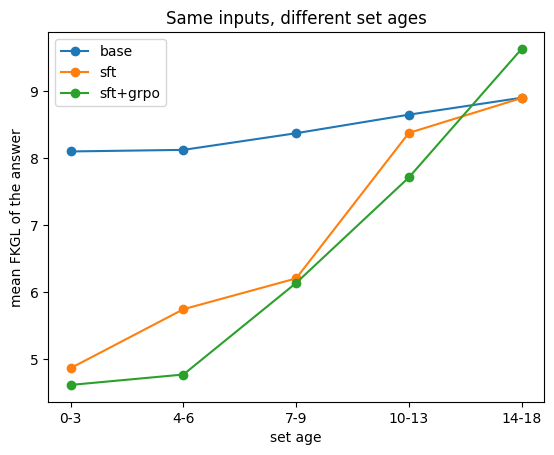

In [ ]:
from scipy.stats import spearmanr

rng = random.Random(SEED)
sweep_rows = rng.sample(HOLDOUT_ROWS, min(AGE_SWEEP_N, len(HOLDOUT_ROWS)))
sweep_prompts = [prompt_messages(a, r["instruction"]) for r in sweep_rows for a in AGES]
sweep_path = f"{OUT_DIR}/age_sweep.json"
SWEEP = json.load(open(sweep_path)) if os.path.exists(sweep_path) else {}
for name in ["base", "sft", "sft+grpo"]:
    if name in SWEEP:
        continue
    m = load_model(name); SWEEP[name] = generate(m, sweep_prompts); del m; gc.collect(); torch.cuda.empty_cache()
    json.dump(SWEEP, open(sweep_path, "w"))

summary, curves = [], {}
for name, preds in SWEEP.items():
    f = np.array([fkgl(p) for p in preds]).reshape(len(sweep_rows), len(AGES))
    rhos = [spearmanr(range(len(AGES)), row).correlation for row in f]
    curves[name] = np.nanmean(f, axis=0)
    summary.append(dict(model=name, mean_spearman=float(np.nanmean(rhos)),
                        share_rho_above_0_5=float(np.nanmean(np.array(rhos) > 0.5))))
sweep_df = pd.DataFrame(summary).set_index("model")
display(sweep_df.round(3)); sweep_df.to_csv(f"{OUT_DIR}/age_sensitivity.csv")
for name, c in curves.items():
    plt.plot(AGES, c, "o-", label=name)
plt.xlabel("set age"); plt.ylabel("mean FKGL of the answer"); plt.title("Same inputs, different set ages"); plt.legend()
plt.savefig(f"{OUT_DIR}/age_sensitivity.png", dpi=150); plt.show()

## 9. Reward-hacking spot check: same inputs, SFT vs SFT+GRPO

In [ ]:
for a in AGES:
    idx = [i for i, r in enumerate(HOLDOUT_ROWS) if r["age"] == a][:2]
    for i in idx:
        print(f"[{a}] child: {HOLDOUT_ROWS[i]['instruction'][:100]}")
        for name in ["sft", "sft+grpo"]:
            print(f"   {name:>9} ({fkgl(PREDS[name][i]):5.1f}): {PREDS[name][i][:220]}")
        print()

[0-3] child: two of them
         sft ( -1.2): Oh, you want two of them! That's so fun! Let's make something!
    sft+grpo (  1.0): Oh, you want two of them! That's so fun! We can tell stories about two things together. Can you tell me about two books?

[0-3] child: it is nearly all gone
         sft (  3.8): Oh no! It's almost gone. That means there are a lot of things left over, which is not quite the same thing as it being all gone completely.
    sft+grpo (  1.8): Oh, that's so sad! The things we have left behind are almost gone now. It is like something special is leaving us.

[4-6] child: put this horses there
         sft (  2.5): Let's put the horses there! Can you remember where the horses are?
    sft+grpo (  2.5): Let's put the horses there! Can you remember where the horses are?

[4-6] child: do the rest of Tilly's hair
         sft (  3.2): Tilly has some very beautiful hair! It looks like a big pink and white fluffy cloud. Maybe you can imagine her hair and how it looks?
